# Freight nowcast: can ports, chokepoints or equities say where freight goes next?

**Target.** Log change in each Baltic index over the next four weeks, sampled every Friday.
**Features**, all known by that Friday (PortWatch lagged a week for publication):
the index's own 1, 4 and 12-week changes; a compact, pre-fixed set of PortWatch signals per
segment (Cape-vs-Suez routing share, Hormuz and Malacca flows, Brazil/Australia/Guinea/Indonesia
dry bulk exports); and the segment's equity basket.
**Method.** Ridge regression (penalty fixed at 10, not tuned), refit weekly on an expanding
window, scored strictly out of sample from January 2021. R² is measured against a random walk
(forecast = no change), the standard bar for freight.

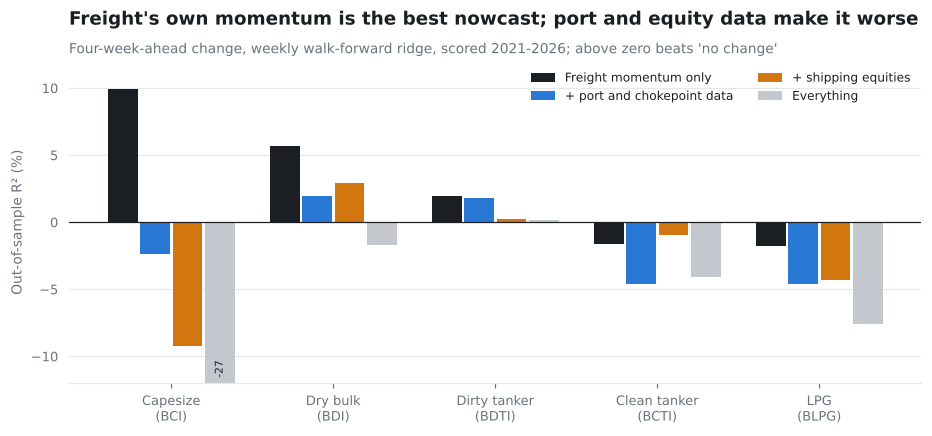

model,all,momentum,momentum+equities,momentum+ports
target,,,,
BCI,-26.6,9.9,-9.2,-2.4
BCTI,-4.1,-1.6,-1.0,-4.6
BDI,-1.7,5.7,2.9,1.9
BDTI,0.2,2.0,0.2,1.8
BLPG,-7.6,-1.8,-4.3,-4.6


In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, matplotlib.pyplot as plt
from shiplab import charts
from shiplab.config import DATA
sc = pd.read_csv(DATA / "results" / "nowcast_scores.csv")
charts.nowcast_scores(sc); plt.show()
sc.pivot(index="target", columns="model", values="oos_r2_vs_random_walk").mul(100).round(1)

**Reading.** Capesize and the BDI carry real short-term momentum: their own recent changes beat
a random walk out of sample (R² of about 10% and 6%). Adding port, chokepoint or equity data
makes every forecast worse. A first version that fed in all 20 PortWatch series overfit badly
(capesize R² of about -200%), so the compact set was fixed before the scored run; both are reported.
Aggregate ship-tracking data describes the freight market the same week. It does not lead it.

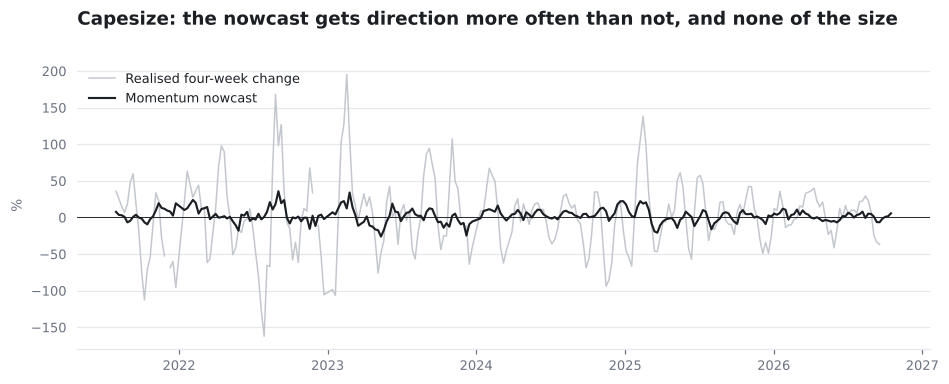

,target,model,as_of,forecast_4w_logchg
0,BDI,momentum,2026-10-16,0.053301
1,BDI,momentum+ports,2026-10-16,0.065524
2,BDI,momentum+equities,2026-10-16,0.058155
3,BDI,all,2026-10-16,0.077812
4,BCI,momentum,2026-10-16,0.057265
5,BCI,momentum+ports,2026-10-16,0.042279
6,BCI,momentum+equities,2026-10-16,0.247541
7,BCI,all,2026-10-16,0.243980
8,BDTI,momentum,2026-10-16,-0.063567
9,BDTI,momentum+ports,2026-10-16,-0.060303


In [2]:
fc = pd.read_csv(DATA / "results" / "nowcast_forecasts.csv", parse_dates=["date"])
g = fc[(fc.target == "BCI") & (fc.model == "momentum")].set_index("date")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(g.actual * 100, color="#C4C8CE", lw=1, label="Realised four-week change")
ax.plot(g.forecast * 100, color="#1B1F24", lw=1.4, label="Momentum nowcast")
ax.axhline(0, color="#1B1F24", lw=0.6); ax.legend(loc="upper left"); ax.set_ylabel("%")
ax.set_title("Capesize: the nowcast gets direction more often than not, and none of the size"); plt.show()
pd.read_csv(DATA / "results" / "nowcast_latest.csv")